# 🧱 Cell 1: 环境配置与路径定义 🛠️

# 首先导入所有必要的库，并定义好你的数据集路径。

In [1]:
import os
import cv2
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import *
import seaborn as sns
from pathlib import Path
from tqdm.notebook import tqdm

# 路径配置 (请确保这些目录已存在)
#RAW_DATA_PATH = r"G:\WSLearning\Data"  # 原始图像根目录
#FEATURE_PATH = r"G:\WSLearning\Data\features"  # 存放提取后的特征文件 (.pt)
MODEL_SAVE_PATH = "best_mil_model.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"当前设备: {device} | 显存限制: 16G (请放心使用)")


当前设备: cuda | 显存限制: 16G (请放心使用)


# 🧱 Cell 2: 特征提取（核心：降维至 512 维） 🔍

# 这里我提供了 ResNet50 作为默认骨干，它最稳定。 

# 我们添加了一个 nn.Linear(2048, 512)  来强制降维。

# 运行建议： 这一步最耗时，建议先拿 2-3 个病人试运行。


## Vit的特征提取效果跟好

In [2]:
import os, torch, timm, numpy as np
from PIL import Image
from pathlib import Path
from tqdm import tqdm
from torchvision import transforms

RAW_PATCH_ROOT = r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data"
SAVE_ROOT = r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data\features.vit"
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

for s in ["train", "val"]:
    for l in ["High", "Low"]:
        os.makedirs(os.path.join(SAVE_ROOT, s, l), exist_ok=True)

# 加载 ViT（timm 支持 PyTorch 1.12）
model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
model.to(DEVICE).eval()
print(f"✅ ViT-Base 加载成功，特征维度: 768")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])

def extract(split, label):
    src = Path(RAW_PATCH_ROOT) / split / label
    dst = Path(SAVE_ROOT) / split / label
    
    patient_dirs = [d for d in src.iterdir() if d.is_dir()]
    print(f"\n{split}/{label}: {len(patient_dirs)} 个病人")
    
    for p_dir in tqdm(patient_dirs):
        save_path = dst / f"{p_dir.name}.pt"
        if save_path.exists(): continue
        
        patches = list(p_dir.glob("*.png")) + list(p_dir.glob("*.jpg"))
        if not patches: continue
        
        all_feats, all_coords = [], []
        for i in range(0, len(patches), 32):
            batch_paths = patches[i:i+32]
            imgs, coords = [], []
            for p in batch_paths:
                try:
                    imgs.append(transform(Image.open(p).convert('RGB')))
                    xy = p.stem.split('_')
                    coords.append([int(xy[0]), int(xy[1])])
                except: continue
            if not imgs: continue
            
            with torch.no_grad():
                feats = model(torch.stack(imgs).to(DEVICE)).cpu()
            all_feats.append(feats)
            all_coords.extend(coords)
        
        if all_feats:
            torch.save({
                'feats': torch.cat(all_feats).numpy(),
                'coords': np.array(all_coords),
                'label': 1 if label == "High" else 0
            }, save_path)

for s in ["train", "val"]:
    for l in ["High", "Low"]:
        extract(s, l)

print(f"\n✅ 提取完成！保存至: {SAVE_ROOT}")


'(MaxRetryError("HTTPSConnectionPool(host='huggingface.co', port=443): Max retries exceeded with url: /timm/vit_base_patch16_224.augreg2_in21k_ft_in1k/resolve/main/model.safetensors (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x000001B9A6EEF3A0>, 'Connection to huggingface.co timed out. (connect timeout=10)'))"), '(Request ID: 80b40334-5138-4e96-837f-313023e0abe9)')' thrown while requesting HEAD https://huggingface.co/timm/vit_base_patch16_224.augreg2_in21k_ft_in1k/resolve/main/model.safetensors
Retrying in 1s [Retry 1/5].
'(MaxRetryError("HTTPSConnectionPool(host='huggingface.co', port=443): Max retries exceeded with url: /timm/vit_base_patch16_224.augreg2_in21k_ft_in1k/resolve/main/model.safetensors (Caused by ConnectTimeoutError(<urllib3.connection.HTTPSConnection object at 0x000001B9A6EEF670>, 'Connection to huggingface.co timed out. (connect timeout=10)'))"), '(Request ID: c465e68a-0987-4826-a069-1e5ba84dc63f)')' thrown while requesting HEAD https:

✅ ViT-Base 加载成功，特征维度: 768

train/High: 60 个病人


100%|███████████████████████████████████████████████████████████████████████████████| 60/60 [1:44:22<00:00, 104.38s/it]



train/Low: 65 个病人


100%|████████████████████████████████████████████████████████████████████████████████| 65/65 [1:05:39<00:00, 60.61s/it]



val/High: 44 个病人


100%|███████████████████████████████████████████████████████████████████████████████| 44/44 [2:50:08<00:00, 232.01s/it]



val/Low: 45 个病人


100%|███████████████████████████████████████████████████████████████████████████████| 45/45 [2:31:01<00:00, 201.36s/it]


✅ 提取完成！保存至: G:\1.Sprouts\CRC.Pathology\20.WSL\Data\features.vit


# ResNet50提取的模型，应该是不如VIT

In [ ]:
class FeatureExtractor(nn.Module):
    def __init__(self, model_name='resnet50'):
        super().__init__()
        if model_name == 'resnet50':
            base = models.resnet50(pretrained=True)
            self.backbone = nn.Sequential(*list(base.children())[:-1])
            in_features = 2048
        # 可选: 'vit_small' 或 'mobilenet_v3' (更省显存)
        
        self.fc = nn.Linear(in_features, 512) # 关键步：降维到 512

    def forward(self, x):
        with torch.no_grad():
            x = self.backbone(x)
            x = x.view(x.size(0), -1)
            return self.fc(x)

def run_extraction():
    extractor = FeatureExtractor().to(device).eval()
    transform = transforms.Compose([
        transforms.Resize((224, 224)),
        transforms.ToTensor(),
        transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    ])

    for split in ['train', 'val']:
        for label, class_val in [('High', 1), ('Low', 0)]:
            src_dir = Path(RAW_DATA_PATH) / split / label
            dst_dir = Path(FEATURE_PATH) / split / label
            dst_dir.mkdir(parents=True, exist_ok=True)

            for patient_path in src_dir.iterdir():
                if not patient_path.is_dir(): continue
                p_id = patient_path.name
                save_file = dst_dir / f"{p_id}.pt"
                if save_file.exists(): continue # 跳过已处理的

                images = list(patient_path.glob("*.png")) + list(patient_path.glob("*.jpg"))
                all_feats, all_coords = [], []

                for i in range(0, len(images), 32): # 16G显存 BatchSize设为32比较稳
                    batch_imgs = torch.stack([transform(Image.open(img).convert('RGB')) for img in images[i:i+32]]).to(device)
                    feats = extractor(batch_imgs).cpu().numpy()
                    all_feats.append(feats)
                    
                    # 解析坐标 (TCGA-A6-2684_..._x18623_y3826)
                    for img_p in images[i:i+32]:
                        parts = img_p.stem.split('_')
                        x = int(parts[-2][1:])
                        y = int(parts[-1][1:])
                        all_coords.append([x, y])
                
                torch.save({'feats': np.concatenate(all_feats), 'coords': np.array(all_coords), 'label': class_val}, save_file)
                print(f"已完成样本: {p_id}, 特征形状: {np.concatenate(all_feats).shape}")

run_extraction() # 取消注释以运行


# 🧱 Cell 3: Attention-MIL 模型定义 🧠

# 这是多实例学习的核心。Attention 机制会学习每个 Patch 的权重。

# MIL多层注意力网络，小样本效果很差，不如单层面的ML

In [14]:
FEATURE_PATH = r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data\features.vit"  # 存放提取后的特征文件 (.pt)
FEATURE_PATH

'G:\\1.Sprouts\\CRC.Pathology\\20.WSL\\Data\\features.vit'

In [15]:
import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
from torch.utils.data import Dataset, DataLoader
from pathlib import Path
from sklearn.metrics import classification_report, roc_auc_score, accuracy_score

# ====================== 全局配置 ======================
# 请确保以下路径和设备已提前定义
# device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
# FEATURE_PATH = "your_feature_root_path"
# MODEL_SAVE_PATH = "best_mil_model.pth"

# ====================== 增强版评估函数 ======================
def evaluate(model, loader):
    """简洁版验证函数：仅计算标准指标"""
    model.eval()
    y_true, y_pred, y_probs = [], [], []
    
    with torch.no_grad():
        for feats, label, _ in loader:
            feats = feats.squeeze(0).to(device)
            label = label.to(device)
            
            logits, _ = model(feats)
            probs = F.softmax(logits, dim=1)
            
            y_probs.append(probs.cpu().numpy()[0])   # [P_low, P_high]
            y_true.append(label.item())
            y_pred.append(torch.argmax(logits, dim=1).item())
    
    y_probs = np.array(y_probs)
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    
    # 计算AUC（仅使用High概率）
    auc_val = 0.5
    if len(np.unique(y_true)) > 1:
        auc_val = roc_auc_score(y_true, y_probs[:, 1])
    else:
        print("⚠️ 警告: 验证集类别单一，无法计算有效 AUC")
    
    report = classification_report(y_true, y_pred, target_names=['Low', 'High'], 
                                   output_dict=True, zero_division=0)
    
    return y_true, y_pred, y_probs, report, auc_val


# ====================== 数据集 ======================
class MILDataset(Dataset):
    def __init__(self, feature_root):
        self.files = list(Path(feature_root).resolve().rglob("*.pt"))
        print(f"✅ 数据集加载完成: {len(self.files)} 个样本")
        
    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        file_path = self.files[idx]
        data = torch.load(file_path)
        path_str = str(file_path).upper()
        
        # 标签映射（保持你确认的原始逻辑，不做反向）
        label = 1 if 'HIGH' in path_str else 0
            
        return torch.from_numpy(data['feats']).float(), torch.tensor(label).long(), str(file_path)


# ====================== 改进版模型（更稳定、更强表达） ======================
class ImprovedGatedAttentionMIL(nn.Module):
    def __init__(self, feature_dim=768, hidden_dim=384, k=64, dropout=0.5):
        super().__init__()
        self.k = k
        
        # 特征归一化
        self.feature_norm = nn.LayerNorm(feature_dim)
        
        # 门控注意力机制（增加Dropout稳定训练）
        self.attention_V = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim), 
            nn.Tanh(), 
            nn.Dropout(dropout)
        )
        self.attention_U = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim), 
            nn.Sigmoid(), 
            nn.Dropout(dropout)
        )
        self.attention_weights = nn.Linear(hidden_dim, 1)
        
        # 更强的分类头（两层 + 渐进Dropout）
        self.classifier = nn.Sequential(
            nn.Linear(feature_dim, hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout + 0.1),
            nn.Linear(hidden_dim, hidden_dim // 2),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim // 2, 2)
        )

    def forward(self, x):
        # x: [N, feature_dim]
        x = self.feature_norm(x)
        N = x.size(0)
        
        # 计算注意力权重
        A_V = self.attention_V(x)
        A_U = self.attention_U(x)
        A = self.attention_weights(A_V * A_U).squeeze(1)  # [N]
        
        # Top-K + 加权聚合（更稳定的实现）
        if self.k < N:
            topk_vals, topk_idx = torch.topk(A, self.k, dim=0)
            A_topk = F.softmax(topk_vals, dim=0)           # [k]
            x_selected = x[topk_idx]                        # [k, D]
            M = torch.sum(A_topk.unsqueeze(1) * x_selected, dim=0)  # [D]
        else:
            A_soft = F.softmax(A, dim=0)
            M = torch.sum(A_soft.unsqueeze(1) * x, dim=0)
        
        # 分类
        logits = self.classifier(M.unsqueeze(0))  # [1, 2] ← 保留batch维度
        return logits, A


# ====================== 训练函数 ======================
history = {'train_loss': [], 'val_loss': [], 'val_auc': [], 'val_acc': []}

def run_optimized_training(epochs=30, lr=1e-4):
    model = ImprovedGatedAttentionMIL(feature_dim=768, hidden_dim=384, k=64, dropout=0.5).to(device)
    
    optimizer = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=1e-3)
    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=5, verbose=True)
    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    best_auc = 0.0
    print(f"🚀 开始训练 Improved Gated Attention MIL (K={model.k})")

    for epoch in range(epochs):
        model.train()
        train_loss = 0.0
        
        for feats, label, _ in train_loader:
            feats = feats.squeeze(0).to(device)
            label = label.to(device)
            
            # 训练时随机Dropout部分Patch（数据增强）
            if feats.size(0) > 100:
                keep_ratio = 0.7
                idx = torch.randperm(feats.size(0))[:int(feats.size(0) * keep_ratio)]
                feats = feats[idx]
            
            optimizer.zero_grad()
            logits, _ = model(feats)
            loss = criterion(logits, label)
            loss.backward()
            optimizer.step()
            
            train_loss += loss.item()
        
        avg_train_loss = train_loss / len(train_loader)
        
        # 验证
        y_true, y_pred, y_probs, report, auc_val = evaluate(model, val_loader)
        val_acc = report['accuracy']
        
        # 记录历史
        history['train_loss'].append(avg_train_loss)
        history['val_auc'].append(auc_val)
        history['val_acc'].append(val_acc)
        
        # 调整学习率（基于AUC）
        scheduler.step(auc_val)
        
        print(f"Epoch [{epoch+1:02d}/{epochs}] | Train Loss: {avg_train_loss:.4f} | "
              f"Val AUC: {auc_val:.4f} | Val Acc: {val_acc:.4f}")
        
        if auc_val > best_auc:
            best_auc = auc_val
            torch.save(model.state_dict(), MODEL_SAVE_PATH)
            print(f"⭐ 新最佳模型保存！AUC: {best_auc:.4f}")


# ====================== 实例化并启动 ======================
# 假设 FEATURE_PATH 已定义
train_loader = DataLoader(MILDataset(Path(FEATURE_PATH) / 'train'), batch_size=1, shuffle=True)
val_loader = DataLoader(MILDataset(Path(FEATURE_PATH) / 'val'), batch_size=1, shuffle=False)

# 启动训练（推荐至少30个epoch）
run_optimized_training(epochs=30, lr=1e-4)

✅ 数据集加载完成: 125 个样本
✅ 数据集加载完成: 89 个样本
🚀 开始训练 Improved Gated Attention MIL (K=64)
Epoch [01/30] | Train Loss: 0.7177 | Val AUC: 0.4778 | Val Acc: 0.5281
⭐ 新最佳模型保存！AUC: 0.4778
Epoch [02/30] | Train Loss: 0.7125 | Val AUC: 0.4727 | Val Acc: 0.5056
Epoch [03/30] | Train Loss: 0.7070 | Val AUC: 0.4914 | Val Acc: 0.4831
⭐ 新最佳模型保存！AUC: 0.4914
Epoch [04/30] | Train Loss: 0.6972 | Val AUC: 0.4949 | Val Acc: 0.5169
⭐ 新最佳模型保存！AUC: 0.4949
Epoch [05/30] | Train Loss: 0.6603 | Val AUC: 0.4859 | Val Acc: 0.5056
Epoch [06/30] | Train Loss: 0.6777 | Val AUC: 0.5268 | Val Acc: 0.4944
⭐ 新最佳模型保存！AUC: 0.5268
Epoch [07/30] | Train Loss: 0.6548 | Val AUC: 0.5576 | Val Acc: 0.5056
⭐ 新最佳模型保存！AUC: 0.5576
Epoch [08/30] | Train Loss: 0.6717 | Val AUC: 0.5571 | Val Acc: 0.4719
Epoch [09/30] | Train Loss: 0.6655 | Val AUC: 0.5641 | Val Acc: 0.4944
⭐ 新最佳模型保存！AUC: 0.5641
Epoch [10/30] | Train Loss: 0.6438 | Val AUC: 0.5753 | Val Acc: 0.5281
⭐ 新最佳模型保存！AUC: 0.5753
Epoch [11/30] | Train Loss: 0.6705 | Val AUC: 0.5732 | V

# Vim + RandomForest将提升模型性能

In [26]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.preprocessing import StandardScaler
import numpy as np

def load_topk_features(feature_root, k=20):
    """
    加载所有 .pt 文件，用 L2 范数选 Top-K patch，
    做 Mean + Max + Std 三种聚合，拼接成 2304 维病人级特征
    """
    X, y = [], []
    for pt_file in Path(feature_root).rglob("*.pt"):
        data  = torch.load(pt_file)
        feats = data['feats']                         # [N, 768]
        norms = np.linalg.norm(feats, axis=1)
        topk_idx = np.argsort(norms)[-k:]
        topk_feats = feats[topk_idx]
        combined = np.concatenate([
            topk_feats.mean(axis=0),
            topk_feats.max(axis=0),
            topk_feats.std(axis=0)
        ])
        label = 1 if 'HIGH' in str(pt_file).upper() else 0
        X.append(combined)
        y.append(label)
    return np.array(X), np.array(y)

print("加载特征...")
X_train, y_train = load_topk_features(Path(FEATURE_PATH) / "train", k=20)
X_val,   y_val   = load_topk_features(Path(FEATURE_PATH) / "val",   k=20)
X_all = np.vstack([X_train, X_val])
y_all = np.concatenate([y_train, y_val])
print(f"总样本: {len(X_all)}, High: {y_all.sum()}, Low: {(y_all==0).sum()}, 特征维度: {X_all.shape[1]}")

# 保存供后续直接使用
X_all_best = X_all
y_all_best = y_all



# 用最优 K=20 的特征，注意修改参数
X_all_best, y_all_best = load_topk_features(
    Path(r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data\features.vit"), k=25
)

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all_best)

# 用网格搜索得到的最优参数
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
aucs, reports = [], []

for fold, (tr_idx, val_idx) in enumerate(skf.split(X_scaled, y_all_best)):
    clf = RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=4,
        class_weight='balanced',
        random_state=42
    )
    clf.fit(X_scaled[tr_idx], y_all_best[tr_idx])
    prob = clf.predict_proba(X_scaled[val_idx])[:, 1]
    pred = clf.predict(X_scaled[val_idx])
    auc = roc_auc_score(y_all_best[val_idx], prob)
    aucs.append(auc)
    print(f"Fold {fold+1}: AUC = {auc:.4f}")

print(f"\n最终结果 | 平均 AUC: {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")


加载特征...
总样本: 214, High: 104, Low: 110, 特征维度: 2304
Fold 1: AUC = 0.4935
Fold 2: AUC = 0.5195
Fold 3: AUC = 0.5108
Fold 4: AUC = 0.6558
Fold 5: AUC = 0.6455

最终结果 | 平均 AUC: 0.5650 ± 0.0705


In [27]:
import joblib
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler

# 构建完整 pipeline（非常重要）
final_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("rf", RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        min_samples_leaf=4,
        class_weight='balanced',
        random_state=42
    ))
])

# 用全部数据训练
final_pipeline.fit(X_all_best, y_all_best)

# 保存模型
joblib.dump(final_pipeline, "vit_rf_k20_pipeline.pkl")

print("✅ 模型已保存为 vit_rf_k20_pipeline.pkl")


✅ 模型已保存为 vit_rf_k20_pipeline.pkl


# 调试这里确定最佳的参数

In [18]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, GridSearchCV
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
import numpy as np

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_all)

# 网格搜索最优参数
param_grid = {
    'n_estimators': [100, 200, 500],
    'max_depth': [None, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

clf = GridSearchCV(
    RandomForestClassifier(class_weight='balanced', random_state=42),
    param_grid,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='roc_auc',
    n_jobs=-1
)
clf.fit(X_scaled, y_all)

print(f"最优参数: {clf.best_params_}")
print(f"最优 AUC: {clf.best_score_:.4f}")


最优参数: {'max_depth': 10, 'min_samples_leaf': 2, 'n_estimators': 100}
最优 AUC: 0.6100


# 调试这里为了确定最佳的K值

In [19]:
for k in [10, 20, 25,30,50,80,100,150,200]:
    X_all_k, y_all_k = load_topk_features(
        Path(r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data\features.vit"), k=k
    )
    X_s = StandardScaler().fit_transform(X_all_k)
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    aucs = [roc_auc_score(
        y_all_k[v], 
        RandomForestClassifier(n_estimators=200, class_weight='balanced', random_state=42)
            .fit(X_s[t], y_all_k[t])
            .predict_proba(X_s[v])[:, 1]
    ) for t, v in skf.split(X_s, y_all_k)]
    print(f"K={k:3d}: AUC = {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")


K= 10: AUC = 0.5232 ± 0.0279
K= 20: AUC = 0.5911 ± 0.0717
K= 25: AUC = 0.6048 ± 0.0746
K= 30: AUC = 0.5682 ± 0.0832
K= 50: AUC = 0.5616 ± 0.0812
K= 80: AUC = 0.5638 ± 0.0564
K=100: AUC = 0.5766 ± 0.0718
K=150: AUC = 0.5558 ± 0.0411
K=200: AUC = 0.5355 ± 0.0300


In [33]:
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from scipy.stats import zscore
import numpy as np
from pathlib import Path
import torch


# ====================== 特征加载（保持你原有逻辑） ======================
def load_topk_features(feature_root, k=20):
    """
    加载所有 .pt 文件，用 L2 范数选 Top-K patch，
    做 Mean + Max + Std 三种聚合，拼接成 2304 维病人级特征
    同时记录每个样本的 patch 总数（用于后续噪声筛查）
    """
    X, y, patch_counts, file_names = [], [], [], []
    
    for pt_file in Path(feature_root).rglob("*.pt"):
        data  = torch.load(pt_file)
        feats = data['feats']                          # [N, 768]
        N     = feats.shape[0]                         # patch 总数
        
        # patch 数量过少时整个切片可能无效（阈值可调）
        if N < 10:
            print(f"⚠️ 跳过 patch 过少的样本: {pt_file.name} (N={N})")
            continue
        
        norms    = np.linalg.norm(feats, axis=1)       # 每个 patch 的 L2 范数
        topk_idx = np.argsort(norms)[-k:]              # 取范数最大的 K 个
        topk_feats = feats[topk_idx]                   # [K, 768]
        
        combined = np.concatenate([
            topk_feats.mean(axis=0),
            topk_feats.max(axis=0),
            topk_feats.std(axis=0)
        ])                                             # [2304]
        
        label = 1 if 'HIGH' in str(pt_file).upper() else 0
        
        X.append(combined)
        y.append(label)
        patch_counts.append(N)
        file_names.append(str(pt_file))
    
    return (np.array(X), np.array(y), 
            np.array(patch_counts), np.array(file_names))


# ====================== 核心：三种噪声筛选策略 ======================
def filter_noisy_samples(X, y, patch_counts, file_names,
                         min_patches=50,
                         zscore_thresh=3.0,
                         lof_contamination=0.1,
                         iforest_contamination=0.1,
                         verbose=True):
    """
    三层噪声过滤（逐步筛选，每层独立可控）：

    第一层 - Patch 数量过滤：
        切片 patch 总数过少，说明组织区域不足，特征不可靠。
        参数: min_patches（默认 50）

    第二层 - Z-score 全局异常检测：
        某个样本的特征向量整体 L2 范数如果极端偏离均值，
        说明其特征分布与其他样本不一致（可能是染色异常/扫描故障）。
        参数: zscore_thresh（默认 3.0，越小越严格）

    第三层 - LOF + Isolation Forest 双重局部异常检测：
        在同类别内部（High 和 Low 分别检测），
        找出与同类其他样本差异极大的离群点。
        双重过滤：两个检测器都认为是异常时才丢弃（避免误删）。
        参数: lof_contamination, iforest_contamination（默认均 0.1）
    """
    mask = np.ones(len(X), dtype=bool)   # True = 保留，False = 丢弃
    
    # === 第一层：Patch 数量过滤 ===
    layer1_mask = patch_counts >= min_patches
    n_removed_l1 = (~layer1_mask).sum()
    mask &= layer1_mask
    
    if verbose:
        print(f"\n📊 噪声过滤统计")
        print(f"├─ 第一层 (Patch数量 < {min_patches}): 移除 {n_removed_l1} 个样本")
    
    # === 第二层：Z-score 全局异常检测 ===
    # 用每个样本特征向量的 L2 范数作为单一异常分数
    sample_norms = np.linalg.norm(X, axis=1)           # [n_samples]
    norm_zscores = np.abs(zscore(sample_norms))         # 标准化后取绝对值
    layer2_mask = norm_zscores < zscore_thresh
    
    # 只统计在第一层通过后的样本中新增的移除数量
    n_removed_l2 = (mask & ~layer2_mask).sum()
    mask &= layer2_mask
    
    if verbose:
        print(f"├─ 第二层 (Z-score > {zscore_thresh}): 移除 {n_removed_l2} 个样本")
    
    # === 第三层：类内 LOF + Isolation Forest 双重检测 ===
    # 分别对 High 和 Low 类别独立检测，避免跨类别干扰
    layer3_mask = np.ones(len(X), dtype=bool)
    
    for class_label in [0, 1]:
        # 当前通过前两层的某类别样本的索引
        class_idx = np.where(mask & (y == class_label))[0]
        
        if len(class_idx) < 10:
            # 样本太少时跳过该类别的 LOF/IForest 检测，避免误删
            print(f"⚠️  类别 {'High' if class_label else 'Low'} 样本数不足10，跳过第三层检测")
            continue
        
        X_class = X[class_idx]   # 当前类别的特征矩阵
        
        # LOF：局部密度异常检测（适合发现边缘样本）
        lof = LocalOutlierFactor(
            n_neighbors=min(5, len(class_idx) - 1),  # 邻居数不超过样本数-1
            contamination=lof_contamination
        )
        lof_labels = lof.fit_predict(X_class)         # -1 = 异常，1 = 正常
        
        # Isolation Forest：树结构异常检测（适合发现极端离群点）
        iforest = IsolationForest(
            contamination=iforest_contamination,
            random_state=42,
            n_estimators=200
        )
        iforest_labels = iforest.fit_predict(X_class) # -1 = 异常，1 = 正常
        
        # 双重过滤：两个检测器都认为是异常时才丢弃
        # 单个检测器认为异常可能是误报，双重确认更保守
        both_anomaly = (lof_labels == -1) & (iforest_labels == -1)
        
        # 将异常标记写回全局 mask
        anomaly_global_idx = class_idx[both_anomaly]
        layer3_mask[anomaly_global_idx] = False
    
    n_removed_l3 = (mask & ~layer3_mask).sum()
    mask &= layer3_mask
    
    if verbose:
        print(f"├─ 第三层 (LOF+IForest双重检测): 移除 {n_removed_l3} 个样本")
        print(f"└─ 过滤后保留: {mask.sum()} / {len(X)} 个样本 "
              f"(High: {(y[mask]==1).sum()}, Low: {(y[mask]==0).sum()})")
        
        # 打印被移除的样本路径（方便人工核查）
        removed_idx = np.where(~mask)[0]
        if len(removed_idx) > 0:
            print(f"\n🗑️  被移除的样本列表:")
            for i in removed_idx:
                reason = []
                if patch_counts[i] < min_patches:
                    reason.append(f"patch数={patch_counts[i]}")
                if np.abs(zscore(np.linalg.norm(X, axis=1)))[i] >= zscore_thresh:
                    reason.append(f"z-score={np.abs(zscore(np.linalg.norm(X, axis=1)))[i]:.2f}")
                print(f"   {Path(file_names[i]).name} | 原因: {', '.join(reason) if reason else 'LOF+IForest异常'}")
    
    return mask


# ====================== 5折交叉验证（带噪声过滤） ======================
def run_cv_with_filter(feature_root, k=25,
                       min_patches=50,
                       zscore_thresh=3.0,
                       lof_contamination=0.1,
                       iforest_contamination=0.1):
    """
    完整流程：加载特征 → 噪声过滤 → 标准化 → 5折交叉验证
    """
    # 1. 加载特征（包含 patch 数量和文件名）
    print("📂 加载特征...")
    X, y, patch_counts, file_names = load_topk_features(feature_root, k=k)
    print(f"原始样本: {len(X)} | High: {y.sum()} | Low: {(y==0).sum()} | 特征维度: {X.shape[1]}")
    
    # 2. 执行噪声过滤（三层策略）
    mask = filter_noisy_samples(
        X, y, patch_counts, file_names,
        min_patches=min_patches,
        zscore_thresh=zscore_thresh,
        lof_contamination=lof_contamination,
        iforest_contamination=iforest_contamination,
        verbose=True
    )
    
    # 3. 应用 mask 得到清洗后的数据集
    X_clean = X[mask]
    y_clean = y[mask]
    
    # 4. 标准化（仅在每折的训练集上 fit，避免数据泄露）
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
    aucs = []
    
    print(f"\n🔁 开始5折交叉验证 (清洗后样本数: {len(X_clean)})")
    
    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_clean, y_clean)):
        # 关键：scaler 只在训练集上 fit，再 transform 验证集
        scaler = StandardScaler()
        X_tr = scaler.fit_transform(X_clean[tr_idx])
        X_val_fold = scaler.transform(X_clean[val_idx])   # 不能 fit_transform
        
        clf = RandomForestClassifier(
            n_estimators=500,
            max_depth=None,
            min_samples_leaf=4,
            class_weight='balanced',
            random_state=42
        )
        clf.fit(X_tr, y_clean[tr_idx])
        
        prob = clf.predict_proba(X_val_fold)[:, 1]
        auc  = roc_auc_score(y_clean[val_idx], prob)
        aucs.append(auc)
        
        print(f"  Fold {fold+1}: AUC = {auc:.4f} "
              f"(val样本: {len(val_idx)}, High: {y_clean[val_idx].sum()}, "
              f"Low: {(y_clean[val_idx]==0).sum()})")
    
    print(f"\n✅ 最终结果 | 平均 AUC: {np.mean(aucs):.4f} ± {np.std(aucs):.4f}")
    return aucs


# ====================== 启动 ======================
aucs = run_cv_with_filter(
    feature_root=Path(FEATURE_PATH),   # 传入包含 train+val 的根目录
    k=60,                              # Top-K patch 数量
    min_patches=500,                    # 第一层：最少 patch 数量
    zscore_thresh=5.0,                 # 第二层：Z-score 阈值
    lof_contamination=0.5,             # 第三层：LOF 异常比例估计
    iforest_contamination=0.5          # 第三层：IForest 异常比例估计
)

📂 加载特征...
原始样本: 214 | High: 104 | Low: 110 | 特征维度: 2304

📊 噪声过滤统计
├─ 第一层 (Patch数量 < 500): 移除 8 个样本
├─ 第二层 (Z-score > 5.0): 移除 0 个样本
├─ 第三层 (LOF+IForest双重检测): 移除 73 个样本
└─ 过滤后保留: 133 / 214 个样本 (High: 64, Low: 69)

🗑️  被移除的样本列表:
   TCGA-5M-AAT6.pt | 原因: LOF+IForest异常
   TCGA-5M-AATE.pt | 原因: LOF+IForest异常
   TCGA-A6-2676.pt | 原因: LOF+IForest异常
   TCGA-A6-5656.pt | 原因: patch数=304
   TCGA-A6-6652.pt | 原因: patch数=344
   TCGA-A6-A56B.pt | 原因: LOF+IForest异常
   TCGA-AA-3555.pt | 原因: LOF+IForest异常
   TCGA-AA-3675.pt | 原因: LOF+IForest异常
   TCGA-AA-3833.pt | 原因: LOF+IForest异常
   TCGA-AA-3870.pt | 原因: LOF+IForest异常
   TCGA-AA-3947.pt | 原因: LOF+IForest异常
   TCGA-AA-3980.pt | 原因: LOF+IForest异常
   TCGA-AA-A00Q.pt | 原因: LOF+IForest异常
   TCGA-AA-A00R.pt | 原因: LOF+IForest异常
   TCGA-AA-A01P.pt | 原因: LOF+IForest异常
   TCGA-AA-A01S.pt | 原因: LOF+IForest异常
   TCGA-AA-A024.pt | 原因: LOF+IForest异常
   TCGA-AD-6548.pt | 原因: LOF+IForest异常
   TCGA-AD-6889.pt | 原因: LOF+IForest异常
   TCGA-AD-A5EK.pt | 原因: LOF+IForest异常

# 🧱 Cell 5: 全指标报告与可视化（ROC/PR/混淆矩阵）📊

# 这个单元格一次性生成你要求的所有指标：AUC, Accuracy, F1, Sensitivity, Specificity, Precision, Recall。

📂 加载特征...
原始样本: 214 | High: 104 | Low: 110 | 特征维度: 2304

📊 噪声过滤统计
├─ 第一层 (Patch数量 < 1000): 移除 22 个样本
├─ 第二层 (Z-score > 20): 移除 0 个样本
├─ 第三层 (LOF+IForest双重): 移除 69 个样本
└─ 过滤后保留: 123 / 214 个样本 (High: 60, Low: 63)

🗑️ 被移除的样本列表:
   TCGA-5M-AAT6.pt | 原因: LOF+IForest
   TCGA-5M-AATE.pt | 原因: LOF+IForest
   TCGA-A6-2676.pt | 原因: LOF+IForest
   TCGA-A6-5656.pt | 原因: patch=304
   TCGA-A6-6652.pt | 原因: patch=344
   TCGA-A6-A56B.pt | 原因: LOF+IForest
   TCGA-AA-3555.pt | 原因: LOF+IForest
   TCGA-AA-3675.pt | 原因: LOF+IForest
   TCGA-AA-3688.pt | 原因: LOF+IForest
   TCGA-AA-3833.pt | 原因: LOF+IForest
   TCGA-AA-3870.pt | 原因: LOF+IForest
   TCGA-AA-3947.pt | 原因: LOF+IForest
   TCGA-AA-3980.pt | 原因: LOF+IForest
   TCGA-AA-A00Q.pt | 原因: LOF+IForest
   TCGA-AA-A00R.pt | 原因: LOF+IForest
   TCGA-AA-A01I.pt | 原因: patch=502
   TCGA-AA-A01S.pt | 原因: LOF+IForest
   TCGA-AA-A024.pt | 原因: LOF+IForest
   TCGA-AD-6548.pt | 原因: LOF+IForest
   TCGA-AD-6889.pt | 原因: LOF+IForest
   ... 共 91 个（已显示前20）

🔁 开始5折交叉验证 (清洗后样本数

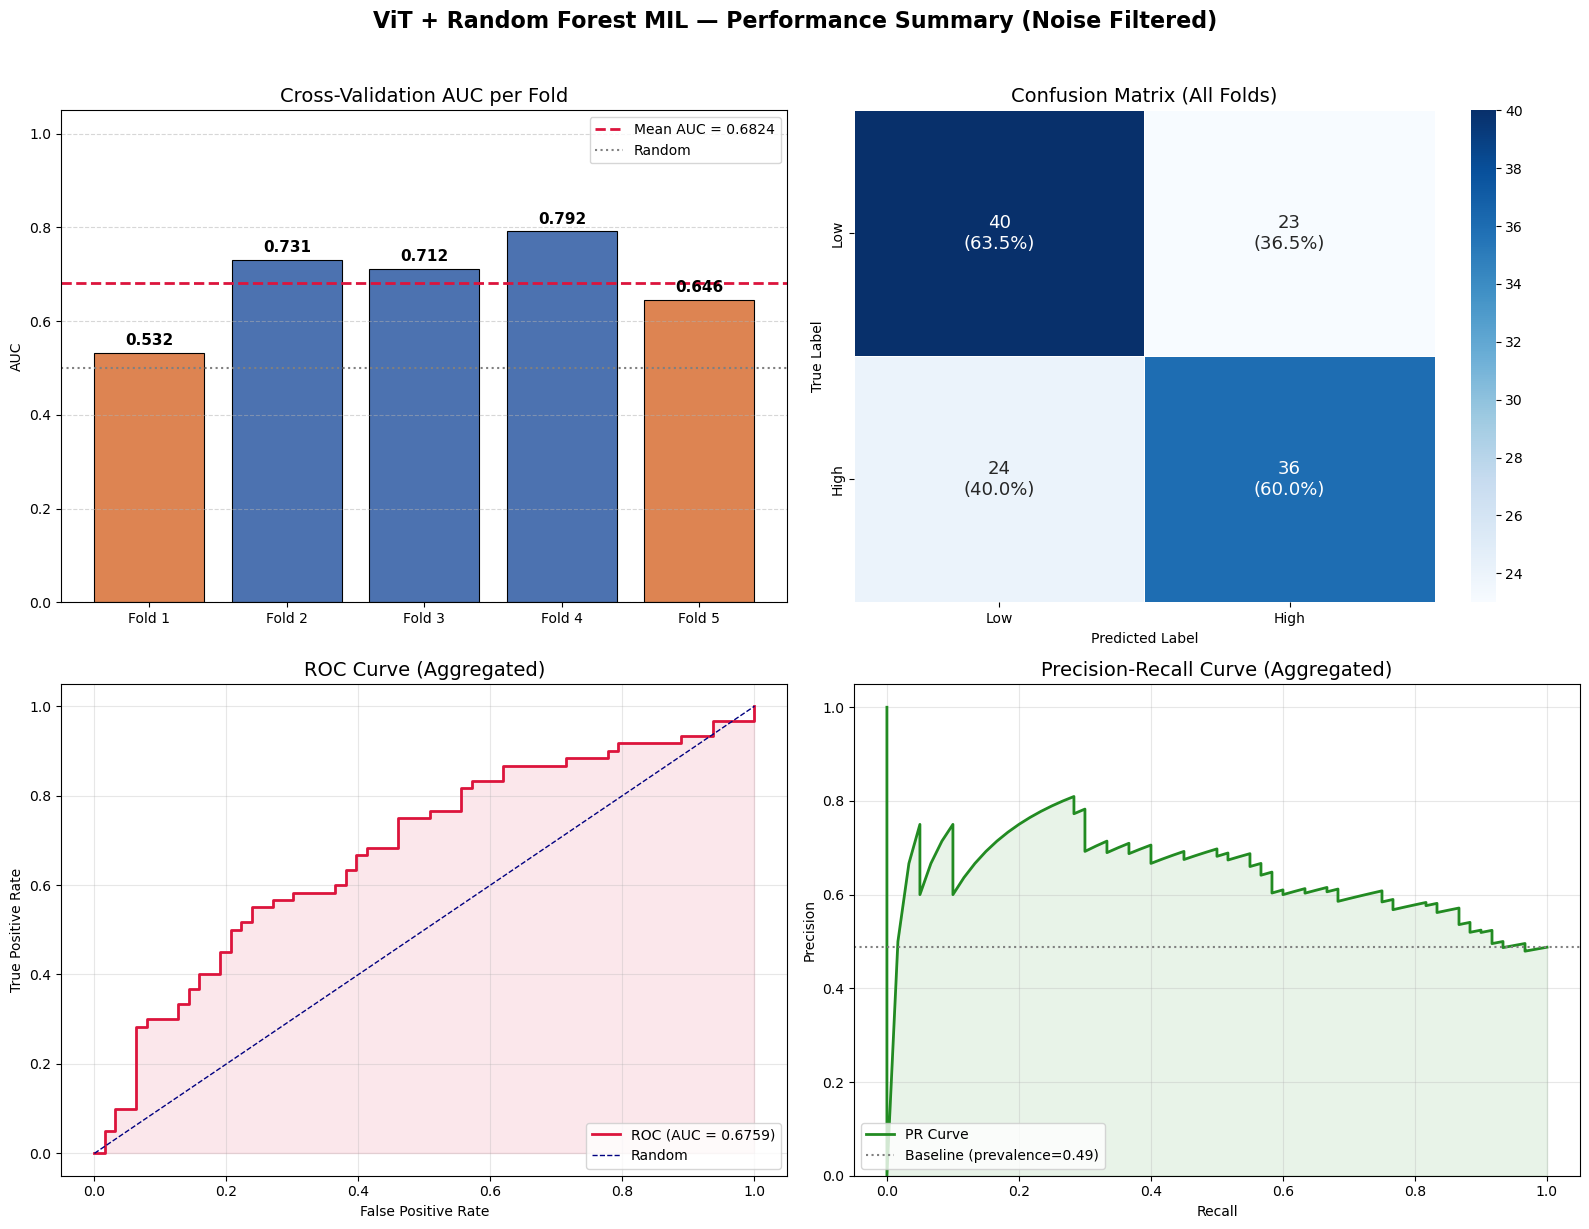

In [52]:
from sklearn.ensemble import RandomForestClassifier, IsolationForest
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, roc_curve, precision_recall_curve
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import LocalOutlierFactor
from scipy.stats import zscore
import numpy as np
from pathlib import Path
import torch
import matplotlib.pyplot as plt
import seaborn as sns

# ====================== 特征加载 ======================
def load_topk_features(feature_root, k=60):
    """
    加载 .pt 文件，用 L2 范数选 Top-K patch，做 Mean+Max+Std 聚合（2304维）
    同时记录 patch 总数和文件名，用于后续噪声筛查
    """
    X, y, patch_counts, file_names = [], [], [], []
    
    for pt_file in Path(feature_root).rglob("*.pt"):
        data = torch.load(pt_file)
        feats = data['feats']                    # [N, 768]
        N = feats.shape[0]
        
        if N < 10:                               # 极少 patch 的样本直接跳过
            print(f"⚠️ 跳过 patch 过少的样本: {pt_file.name} (N={N})")
            continue
        
        norms = np.linalg.norm(feats, axis=1)
        topk_idx = np.argsort(norms)[-k:]
        topk_feats = feats[topk_idx]
        
        combined = np.concatenate([
            topk_feats.mean(axis=0),
            topk_feats.max(axis=0),
            topk_feats.std(axis=0)
        ])
        
        label = 1 if 'HIGH' in str(pt_file).upper() else 0
        
        X.append(combined)
        y.append(label)
        patch_counts.append(N)
        file_names.append(str(pt_file))
    
    return (np.array(X), np.array(y), np.array(patch_counts), np.array(file_names))


# ====================== 三层噪声过滤 ======================
def filter_noisy_samples(X, y, patch_counts, file_names,
                         min_patches=100,          # TCGA 数据建议从100开始
                         zscore_thresh=4.0,        # 稍宽松，避免误删过多
                         lof_contamination=0.15,
                         iforest_contamination=0.15,
                         verbose=True):
    """三层逐步过滤：Patch数量 → Z-score全局异常 → 类内 LOF+IForest 双重检测"""
    mask = np.ones(len(X), dtype=bool)
    
    # 第一层：Patch 数量过滤
    layer1_mask = patch_counts >= min_patches
    n_removed_l1 = (~layer1_mask).sum()
    mask &= layer1_mask
    if verbose:
        print(f"\n📊 噪声过滤统计")
        print(f"├─ 第一层 (Patch数量 < {min_patches}): 移除 {n_removed_l1} 个样本")
    
    # 第二层：Z-score 全局异常检测（基于特征向量范数）
    sample_norms = np.linalg.norm(X, axis=1)
    norm_zscores = np.abs(zscore(sample_norms))
    layer2_mask = norm_zscores < zscore_thresh
    n_removed_l2 = (mask & ~layer2_mask).sum()
    mask &= layer2_mask
    if verbose:
        print(f"├─ 第二层 (Z-score > {zscore_thresh}): 移除 {n_removed_l2} 个样本")
    
    # 第三层：类内 LOF + Isolation Forest 双重检测（更保守）
    layer3_mask = np.ones(len(X), dtype=bool)
    for class_label in [0, 1]:
        class_idx = np.where(mask & (y == class_label))[0]
        if len(class_idx) < 10:
            print(f"⚠️ 类别 {'High' if class_label else 'Low'} 样本不足10，跳过第三层")
            continue
        
        X_class = X[class_idx]
        
        lof = LocalOutlierFactor(n_neighbors=min(5, len(class_idx)-1),
                                 contamination=lof_contamination)
        lof_labels = lof.fit_predict(X_class)
        
        iforest = IsolationForest(contamination=iforest_contamination,
                                  random_state=42, n_estimators=200)
        iforest_labels = iforest.fit_predict(X_class)
        
        both_anomaly = (lof_labels == -1) & (iforest_labels == -1)
        anomaly_global_idx = class_idx[both_anomaly]
        layer3_mask[anomaly_global_idx] = False
    
    n_removed_l3 = (mask & ~layer3_mask).sum()
    mask &= layer3_mask
    
    if verbose:
        print(f"├─ 第三层 (LOF+IForest双重): 移除 {n_removed_l3} 个样本")
        print(f"└─ 过滤后保留: {mask.sum()} / {len(X)} 个样本 "
              f"(High: {(y[mask]==1).sum()}, Low: {(y[mask]==0).sum()})")
    
    # 打印被移除样本（便于人工检查）
    removed_idx = np.where(~mask)[0]
    if len(removed_idx) > 0 and verbose:
        print(f"\n🗑️ 被移除的样本列表:")
        for i in removed_idx[:20]:   # 只显示前20个，避免输出过长
            reason = []
            if patch_counts[i] < min_patches:
                reason.append(f"patch={patch_counts[i]}")
            if norm_zscores[i] >= zscore_thresh:
                reason.append(f"z-score={norm_zscores[i]:.2f}")
            print(f"   {Path(file_names[i]).name} | 原因: {', '.join(reason) if reason else 'LOF+IForest'}")
        if len(removed_idx) > 20:
            print(f"   ... 共 {len(removed_idx)} 个（已显示前20）")
    
    return mask


# ====================== 绘图函数（你提供的版本，略微优化） ======================
def plot_rf_performance(X_all, y_all, k_folds=5):
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_all)

    skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

    fold_aucs = []
    all_y_true, all_y_prob, all_y_pred = [], [], []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_scaled, y_all)):
        clf = RandomForestClassifier(
            n_estimators=500, max_depth=None, min_samples_leaf=4,
            class_weight='balanced', random_state=42
        )
        clf.fit(X_scaled[tr_idx], y_all[tr_idx])
        prob = clf.predict_proba(X_scaled[val_idx])[:, 1]
        pred = clf.predict(X_scaled[val_idx])

        auc = roc_auc_score(y_all[val_idx], prob)
        fold_aucs.append(auc)

        all_y_true.extend(y_all[val_idx])
        all_y_prob.extend(prob)
        all_y_pred.extend(pred)

    all_y_true = np.array(all_y_true)
    all_y_prob = np.array(all_y_prob)
    all_y_pred = np.array(all_y_pred)

    # ---- 绘图 ----
    fig, axes = plt.subplots(2, 2, figsize=(16, 12))
    plt.subplots_adjust(hspace=0.35, wspace=0.3)

    # A. 各折 AUC
    colors = ['#4C72B0' if auc >= np.mean(fold_aucs) else '#DD8452' for auc in fold_aucs]
    bars = axes[0, 0].bar([f'Fold {i+1}' for i in range(k_folds)], fold_aucs,
                          color=colors, edgecolor='black', linewidth=0.8)
    axes[0, 0].axhline(np.mean(fold_aucs), color='crimson', linestyle='--', lw=2,
                       label=f'Mean AUC = {np.mean(fold_aucs):.4f}')
    axes[0, 0].axhline(0.5, color='gray', linestyle=':', lw=1.5, label='Random')
    for bar, auc in zip(bars, fold_aucs):
        axes[0, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                        f'{auc:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    axes[0, 0].set_ylim(0, 1.05)
    axes[0, 0].set_title('Cross-Validation AUC per Fold', fontsize=14)
    axes[0, 0].set_ylabel('AUC')
    axes[0, 0].legend(fontsize=10)
    axes[0, 0].grid(True, linestyle='--', alpha=0.5, axis='y')

    # B. 混淆矩阵
    cm = confusion_matrix(all_y_true, all_y_pred)
    cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f'{cm[i,j]}\n({cm_percent[i,j]:.1f}%)' for j in range(cm.shape[1])]
                      for i in range(cm.shape[0])])
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', ax=axes[0, 1],
                xticklabels=['Low', 'High'], yticklabels=['Low', 'High'],
                annot_kws={"size": 13}, linewidths=0.5)
    axes[0, 1].set_title('Confusion Matrix (All Folds)', fontsize=14)
    axes[0, 1].set_xlabel('Predicted Label')
    axes[0, 1].set_ylabel('True Label')

    # C. ROC 曲线
    overall_auc = roc_auc_score(all_y_true, all_y_prob)
    fpr, tpr, _ = roc_curve(all_y_true, all_y_prob)
    axes[1, 0].plot(fpr, tpr, color='crimson', lw=2, label=f'ROC (AUC = {overall_auc:.4f})')
    axes[1, 0].fill_between(fpr, tpr, alpha=0.1, color='crimson')
    axes[1, 0].plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random')
    axes[1, 0].set_title('ROC Curve (Aggregated)', fontsize=14)
    axes[1, 0].set_xlabel('False Positive Rate')
    axes[1, 0].set_ylabel('True Positive Rate')
    axes[1, 0].legend(loc='lower right', fontsize=10)
    axes[1, 0].grid(True, alpha=0.3)

    # D. PR 曲线
    precision, recall, _ = precision_recall_curve(all_y_true, all_y_prob)
    baseline = all_y_true.sum() / len(all_y_true)
    axes[1, 1].plot(recall, precision, color='forestgreen', lw=2, label='PR Curve')
    axes[1, 1].axhline(baseline, color='gray', linestyle=':', lw=1.5,
                       label=f'Baseline (prevalence={baseline:.2f})')
    axes[1, 1].fill_between(recall, precision, alpha=0.1, color='forestgreen')
    axes[1, 1].set_title('Precision-Recall Curve (Aggregated)', fontsize=14)
    axes[1, 1].set_xlabel('Recall')
    axes[1, 1].set_ylabel('Precision')
    axes[1, 1].set_ylim(0, 1.05)
    axes[1, 1].legend(loc='lower left', fontsize=10)
    axes[1, 1].grid(True, alpha=0.3)

    # 汇总报告
    print(f"\n{'='*45}")
    print(f"  5-Fold CV Summary (After Noise Filtering)")
    print(f"{'='*45}")
    print(f"  Mean AUC : {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}")
    print(f"  Best AUC : {max(fold_aucs):.4f} (Fold {np.argmax(fold_aucs)+1})")
    print(f"  Aggregated AUC: {overall_auc:.4f}")
    print(f"\n{classification_report(all_y_true, all_y_pred, target_names=['Low', 'High'])}")

    plt.suptitle('ViT + Random Forest MIL — Performance Summary (Noise Filtered)',
                 fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    plt.show()


# ====================== 主流程：过滤 + 交叉验证 + 绘图 ======================
def run_filtered_rf_pipeline(feature_root, k=60):
    print("📂 加载特征...")
    X, y, patch_counts, file_names = load_topk_features(feature_root, k=k)
    print(f"原始样本: {len(X)} | High: {y.sum()} | Low: {(y==0).sum()} | 特征维度: {X.shape[1]}")
    
    # 执行噪声过滤
    mask = filter_noisy_samples(X, y, patch_counts, file_names,
                                min_patches=1000,
                                zscore_thresh=20,
                                lof_contamination=0.5,
                                iforest_contamination=0.5,
                                verbose=True)
    
    X_clean = X[mask]
    y_clean = y[mask]
    
    print(f"\n🔁 开始5折交叉验证 (清洗后样本数: {len(X_clean)})")
    plot_rf_performance(X_clean, y_clean, k_folds=5)


# ====================== 启动 ======================
# 请确保 FEATURE_PATH 已正确定义
aucs = run_filtered_rf_pipeline(feature_root=Path(FEATURE_PATH), k=60)

# 绘制PDF版本结果

In [69]:
# ====================== 绘图函数（拆分为独立PDF + 文字修复） ======================
def plot_rf_performance(X_all, y_all, k_folds=5, save_prefix="rf_performance"):
    """
    绘制 Random Forest 性能评估图，并分别保存为 PDF
    save_prefix: 文件名前缀，例如 "rf_performance"
    """
    scaler = StandardScaler()
    X_scaled = scaler.fit_transform(X_all)

    skf = StratifiedKFold(n_splits=k_folds, shuffle=True, random_state=42)

    fold_aucs = []
    all_y_true, all_y_prob, all_y_pred = [], [], []

    for fold, (tr_idx, val_idx) in enumerate(skf.split(X_scaled, y_all)):
        clf = RandomForestClassifier(
            n_estimators=500, max_depth=None, min_samples_leaf=4,
            class_weight='balanced', random_state=42
        )
        clf.fit(X_scaled[tr_idx], y_all[tr_idx])
        prob = clf.predict_proba(X_scaled[val_idx])[:, 1]
        pred = clf.predict(X_scaled[val_idx])

        auc = roc_auc_score(y_all[val_idx], prob)
        fold_aucs.append(auc)

        all_y_true.extend(y_all[val_idx])
        all_y_prob.extend(prob)
        all_y_pred.extend(pred)

    all_y_true = np.array(all_y_true)
    all_y_prob = np.array(all_y_prob)
    all_y_pred = np.array(all_y_pred)

    # ====================== 字体配置（防止 PDF 文字拆分） ======================
    plt.rcParams['pdf.fonttype'] = 42
    plt.rcParams['ps.fonttype'] = 42
    plt.rcParams['font.family'] = 'sans-serif'
    plt.rcParams['font.sans-serif'] = ['Arial', 'Helvetica', 'DejaVu Sans']

    # ====================== 1. 各折 AUC 柱状图 ======================
    fig1, ax1 = plt.subplots(figsize=(8, 6))
    colors = ['#4C72B0' if auc >= np.mean(fold_aucs) else '#DD8452' for auc in fold_aucs]
    bars = ax1.bar([f'Fold {i+1}' for i in range(k_folds)], fold_aucs,
                   color=colors, edgecolor='black', linewidth=0.8)
    ax1.axhline(np.mean(fold_aucs), color='crimson', linestyle='--', lw=2,
                label=f'Mean AUC = {np.mean(fold_aucs):.4f}')
    ax1.axhline(0.5, color='gray', linestyle=':', lw=1.5, label='Random')
    for bar, auc in zip(bars, fold_aucs):
        ax1.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                 f'{auc:.3f}', ha='center', va='bottom', fontsize=11, fontweight='bold')
    ax1.set_ylim(0, 1.05)
    ax1.set_title('Cross-Validation AUC per Fold', fontsize=14)
    ax1.set_ylabel('AUC')
    ax1.legend(fontsize=10)
    ax1.grid(True, linestyle='--', alpha=0.5, axis='y')

    fig1.suptitle('ViT + Random Forest MIL — AUC per Fold', 
                  fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    pdf1 = f"{save_prefix}_auc_per_fold.pdf"
    plt.savefig(pdf1, dpi=300, bbox_inches='tight')
    plt.close(fig1)
    print(f"✅ 已保存: {pdf1}")

    # ====================== 2. 混淆矩阵 ======================
    fig2, ax2 = plt.subplots(figsize=(7, 6))
    cm = confusion_matrix(all_y_true, all_y_pred)
    cm_percent = cm.astype(float) / cm.sum(axis=1, keepdims=True) * 100
    annot = np.array([[f'{cm[i,j]}\n({cm_percent[i,j]:.1f}%)' for j in range(cm.shape[1])]
                      for i in range(cm.shape[0])])
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', ax=ax2,
                xticklabels=['Low', 'High'], yticklabels=['Low', 'High'],
                annot_kws={"size": 13}, linewidths=0.5)
    ax2.set_title('Confusion Matrix (All Folds)', fontsize=14)
    ax2.set_xlabel('Predicted Label')
    ax2.set_ylabel('True Label')

    fig2.suptitle('ViT + Random Forest MIL — Confusion Matrix', 
                  fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    pdf2 = f"{save_prefix}_confusion_matrix.pdf"
    plt.savefig(pdf2, dpi=300, bbox_inches='tight')
    plt.close(fig2)
    print(f"✅ 已保存: {pdf2}")

    # ====================== 3. ROC 曲线 ======================
    fig3, ax3 = plt.subplots(figsize=(8, 6))
    overall_auc = roc_auc_score(all_y_true, all_y_prob)
    fpr, tpr, _ = roc_curve(all_y_true, all_y_prob)
    ax3.plot(fpr, tpr, color='crimson', lw=2, label=f'ROC (AUC = {overall_auc:.4f})')
    ax3.fill_between(fpr, tpr, alpha=0.1, color='crimson')
    ax3.plot([0, 1], [0, 1], color='navy', lw=1, linestyle='--', label='Random')
    ax3.set_title('ROC Curve (Aggregated)', fontsize=14)
    ax3.set_xlabel('False Positive Rate')
    ax3.set_ylabel('True Positive Rate')
    ax3.legend(loc='lower right', fontsize=10)
    ax3.grid(True, alpha=0.3)

    fig3.suptitle('ViT + Random Forest MIL — ROC Curve', 
                  fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    pdf3 = f"{save_prefix}_roc_curve.pdf"
    plt.savefig(pdf3, dpi=300, bbox_inches='tight')
    plt.close(fig3)
    print(f"✅ 已保存: {pdf3}")

    # ====================== 4. PR 曲线 ======================
    fig4, ax4 = plt.subplots(figsize=(8, 6))
    precision, recall, _ = precision_recall_curve(all_y_true, all_y_prob)
    baseline = all_y_true.sum() / len(all_y_true)
    ax4.plot(recall, precision, color='forestgreen', lw=2, label='PR Curve')
    ax4.axhline(baseline, color='gray', linestyle=':', lw=1.5,
                label=f'Baseline (prevalence={baseline:.2f})')
    ax4.fill_between(recall, precision, alpha=0.1, color='forestgreen')
    ax4.set_title('Precision-Recall Curve (Aggregated)', fontsize=14)
    ax4.set_xlabel('Recall')
    ax4.set_ylabel('Precision')
    ax4.set_ylim(0, 1.05)
    ax4.legend(loc='lower left', fontsize=10)
    ax4.grid(True, alpha=0.3)

    fig4.suptitle('ViT + Random Forest MIL — Precision-Recall Curve', 
                  fontsize=16, fontweight='bold', y=1.02)
    plt.tight_layout()
    pdf4 = f"{save_prefix}_pr_curve.pdf"
    plt.savefig(pdf4, dpi=300, bbox_inches='tight')
    plt.close(fig4)
    print(f"✅ 已保存: {pdf4}")

    # ====================== 打印汇总报告（保持不变） ======================
    print(f"\n{'='*45}")
    print(f"  5-Fold CV Summary (After Noise Filtering)")
    print(f"{'='*45}")
    print(f"  Mean AUC : {np.mean(fold_aucs):.4f} ± {np.std(fold_aucs):.4f}")
    print(f"  Best AUC : {max(fold_aucs):.4f} (Fold {np.argmax(fold_aucs)+1})")
    print(f"  Aggregated AUC: {overall_auc:.4f}")
    print(f"\n{classification_report(all_y_true, all_y_pred, target_names=['Low', 'High'])}")

    # ====================== 可选：整体预览（仍显示在屏幕） ======================
    print(f"\n📊 所有 PDF 已分别保存（前缀: {save_prefix}）")
    plt.show()   # 如果不需要显示，可以注释掉这一行

In [70]:
# ====================== 主流程：过滤 + 交叉验证 + 绘图 ======================
def run_filtered_rf_pipeline(feature_root, k=60):
    print("📂 加载特征...")
    X, y, patch_counts, file_names = load_topk_features(feature_root, k=k)
    print(f"原始样本: {len(X)} | High: {y.sum()} | Low: {(y==0).sum()} | 特征维度: {X.shape[1]}")
    
    # 执行噪声过滤
    mask = filter_noisy_samples(X, y, patch_counts, file_names,
                                min_patches=1000,
                                zscore_thresh=20,
                                lof_contamination=0.5,
                                iforest_contamination=0.5,
                                verbose=True)
    
    X_clean = X[mask]
    y_clean = y[mask]
    
    print(f"\n🔁 开始5折交叉验证 (清洗后样本数: {len(X_clean)})")
    
    # 新增 save_prefix 参数，可自定义前缀
    plot_rf_performance(X_clean, y_clean, k_folds=5, 
                        save_prefix="rf_performance_clean")


# ====================== 启动 ======================
# 请确保 FEATURE_PATH 已正确定义
aucs = run_filtered_rf_pipeline(feature_root=Path(FEATURE_PATH), k=60)

📂 加载特征...
原始样本: 214 | High: 104 | Low: 110 | 特征维度: 2304

📊 噪声过滤统计
├─ 第一层 (Patch数量 < 1000): 移除 22 个样本
├─ 第二层 (Z-score > 20): 移除 0 个样本
├─ 第三层 (LOF+IForest双重): 移除 69 个样本
└─ 过滤后保留: 123 / 214 个样本 (High: 60, Low: 63)

🗑️ 被移除的样本列表:
   TCGA-5M-AAT6.pt | 原因: LOF+IForest
   TCGA-5M-AATE.pt | 原因: LOF+IForest
   TCGA-A6-2676.pt | 原因: LOF+IForest
   TCGA-A6-5656.pt | 原因: patch=304
   TCGA-A6-6652.pt | 原因: patch=344
   TCGA-A6-A56B.pt | 原因: LOF+IForest
   TCGA-AA-3555.pt | 原因: LOF+IForest
   TCGA-AA-3675.pt | 原因: LOF+IForest
   TCGA-AA-3688.pt | 原因: LOF+IForest
   TCGA-AA-3833.pt | 原因: LOF+IForest
   TCGA-AA-3870.pt | 原因: LOF+IForest
   TCGA-AA-3947.pt | 原因: LOF+IForest
   TCGA-AA-3980.pt | 原因: LOF+IForest
   TCGA-AA-A00Q.pt | 原因: LOF+IForest
   TCGA-AA-A00R.pt | 原因: LOF+IForest
   TCGA-AA-A01I.pt | 原因: patch=502
   TCGA-AA-A01S.pt | 原因: LOF+IForest
   TCGA-AA-A024.pt | 原因: LOF+IForest
   TCGA-AD-6548.pt | 原因: LOF+IForest
   TCGA-AD-6889.pt | 原因: LOF+IForest
   ... 共 91 个（已显示前20）

🔁 开始5折交叉验证 (清洗后样本数

# 输出表格做机器学习

In [44]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import roc_auc_score
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd
import torch
from pathlib import Path

FEATURE_PATH = r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data\features.vit"

def load_topk_features(feature_root, k=20):
   X, y, names = [], [], []
   for pt_file in Path(feature_root).rglob("*.pt"):
       data  = torch.load(pt_file)
       feats = data['feats']
       norms = np.linalg.norm(feats, axis=1)
       topk_idx   = np.argsort(norms)[-k:]
       topk_feats = feats[topk_idx]
       combined = np.concatenate([
           topk_feats.mean(axis=0),
           topk_feats.max(axis=0),
           topk_feats.std(axis=0)
       ])
       label = 1 if 'HIGH' in str(pt_file).upper() else 0
       X.append(combined)
       y.append(label)
       names.append(pt_file.stem)
   return np.array(X), np.array(y), names

# ── 加载特征 ──────────────────────────────────────────
print("加载特征...")
X_train, y_train, names_train = load_topk_features(Path(FEATURE_PATH) / "train", k=20)
X_val,   y_val,   names_val   = load_topk_features(Path(FEATURE_PATH) / "val",   k=20)

X_all_best = np.vstack([X_train, X_val])
y_all_best = np.concatenate([y_train, y_val])
names_all  = names_train + names_val

print(f"总样本: {len(X_all_best)}, High: {y_all_best.sum()}, "
     f"Low: {(y_all_best==0).sum()}, 特征维度: {X_all_best.shape[1]}")

# ── 标准化（分别对train/val用同一个scaler） ───────────
scaler   = StandardScaler()
X_scaled = scaler.fit_transform(X_all_best)

X_train_scaled = scaler.transform(X_train)
X_val_scaled   = scaler.transform(X_val)

# ── 构造列名 ──────────────────────────────────────────
n_feat    = 768
agg_names = (
   [f"mean_{i}" for i in range(n_feat)] +
   [f"max_{i}"  for i in range(n_feat)] +
   [f"std_{i}"  for i in range(n_feat)]
)

def save_csv(X, y, names, path):
   df = pd.DataFrame(X, columns=agg_names)
   df.insert(0, "label",   y)
   df.insert(0, "patient", names)
   df.to_csv(path, index=False)
   print(f"已保存: {path}  shape={df.shape}")

# ── 导出三个CSV ───────────────────────────────────────
save_csv(X_train_scaled, y_train, names_train, r"H:\features_train.csv")
save_csv(X_val_scaled,   y_val,   names_val,   r"H:\features_val.csv")
save_csv(X_scaled,       y_all_best, names_all, r"H:\features_all.csv")

加载特征...
总样本: 214, High: 104, Low: 110, 特征维度: 2304
已保存: H:\features_train.csv  shape=(125, 2306)
已保存: H:\features_val.csv  shape=(89, 2306)
已保存: H:\features_all.csv  shape=(214, 2306)


In [41]:
import os 
os.getcwd()

'G:\\1.Sprouts\\CRC.Pathology\\20.WSL'

# 🧱 Cell 6: 针对 Patch 的 Grad-CAM 实现 🔬

# 注意： Grad-CAM 是对卷积神经网络（ResNet50）的可解释性。

# 它的逻辑是：如果 MIL 认为某个 Patch 的 Attention 权重很高，

# 那么我们想知道“这个 Patch 里到底是什么特征让 ResNet 觉得它是 High”。

In [53]:
import torch
import numpy as np
from pathlib import Path
import re

def fix_coords(feature_root, patch_root):
    for pt_file in Path(feature_root).rglob("*.pt"):
        data = torch.load(pt_file)
        
        if len(data.get('coords', [])) > 0:
            continue
        
        parts = pt_file.parts
        split   = parts[-3]
        label   = parts[-2]
        patient = pt_file.stem
        
        patch_dir = Path(patch_root) / split / label / patient
        if not patch_dir.exists():
            print(f"⚠️ 找不到: {patch_dir}")
            continue
        
        patch_files = list(patch_dir.glob("*.png")) + list(patch_dir.glob("*.jpg"))
        
        coords = []
        for p in patch_files:
            # 匹配 x71492_y3027 格式
            m = re.search(r'_x(\d+)_y(\d+)', p.stem)
            if m:
                coords.append([int(m.group(1)), int(m.group(2))])
            else:
                coords.append([0, 0])
        
        data['coords'] = np.array(coords)
        torch.save(data, pt_file)
        print(f"✅ {pt_file.name}: 补充了 {len(coords)} 个坐标")

fix_coords(
    feature_root=r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data\features.vit",
    patch_root=r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data"
)


✅ TCGA-5M-AAT6.pt: 补充了 16443 个坐标
✅ TCGA-5M-AATE.pt: 补充了 27159 个坐标
✅ TCGA-A6-2676.pt: 补充了 1781 个坐标
✅ TCGA-A6-2681.pt: 补充了 1470 个坐标
✅ TCGA-A6-2683.pt: 补充了 1339 个坐标
✅ TCGA-A6-3808.pt: 补充了 2318 个坐标
✅ TCGA-A6-4105.pt: 补充了 2395 个坐标
✅ TCGA-A6-5656.pt: 补充了 304 个坐标
✅ TCGA-A6-5664.pt: 补充了 3366 个坐标
✅ TCGA-A6-6650.pt: 补充了 1557 个坐标
✅ TCGA-A6-6652.pt: 补充了 344 个坐标
✅ TCGA-A6-A56B.pt: 补充了 6118 个坐标
✅ TCGA-AA-3520.pt: 补充了 2414 个坐标
✅ TCGA-AA-3524.pt: 补充了 2393 个坐标
✅ TCGA-AA-3526.pt: 补充了 2789 个坐标
✅ TCGA-AA-3532.pt: 补充了 2168 个坐标
✅ TCGA-AA-3555.pt: 补充了 3709 个坐标
✅ TCGA-AA-3673.pt: 补充了 1418 个坐标
✅ TCGA-AA-3675.pt: 补充了 2191 个坐标
✅ TCGA-AA-3680.pt: 补充了 4060 个坐标
✅ TCGA-AA-3688.pt: 补充了 2926 个坐标
✅ TCGA-AA-3692.pt: 补充了 2312 个坐标
✅ TCGA-AA-3693.pt: 补充了 3631 个坐标
✅ TCGA-AA-3710.pt: 补充了 5589 个坐标
✅ TCGA-AA-3833.pt: 补充了 4214 个坐标
✅ TCGA-AA-3841.pt: 补充了 4434 个坐标
✅ TCGA-AA-3844.pt: 补充了 1305 个坐标
✅ TCGA-AA-3850.pt: 补充了 1734 个坐标
✅ TCGA-AA-3867.pt: 补充了 2168 个坐标
✅ TCGA-AA-3869.pt: 补充了 2049 个坐标
✅ TCGA-AA-3870.pt: 补充了 1580 个坐标
✅ TCGA-A

C:\Users\niyuan\.conda\envs\deeppt\lib\site-packages\torch\nn\modules\module.py:1053: UserWarning: Using a non-full backward hook when the forward contains multiple autograd Nodes is deprecated and will be removed in future versions. This hook will be missing some grad_input. Please use register_full_backward_hook to get the documented behavior.
  warnings.warn("Using a non-full backward hook when the forward contains multiple autograd Nodes "


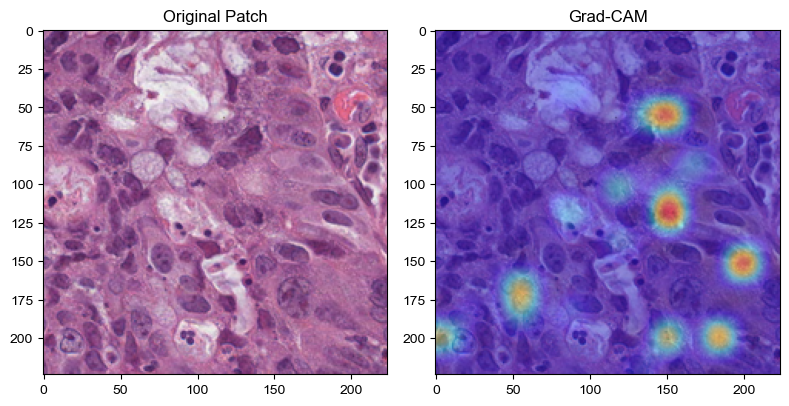

In [71]:
# ============================================================
# %% [7] ViT Grad-CAM（单张 Patch）
# ============================================================
class ViTGradCAM:
    def __init__(self, model):
        self.model      = model
        self.gradients  = None
        self.activations = None
        target_layer = model.blocks[-1].norm1
        target_layer.register_forward_hook(self._save_activation)
        target_layer.register_backward_hook(self._save_gradient)

    def _save_activation(self, module, input, output):
        self.activations = output

    def _save_gradient(self, module, grad_input, grad_output):
        self.gradients = grad_output[0]

    def generate(self, input_tensor):          # ← 只改了这个函数
        self.model.eval()
        output = self.model(input_tensor)
        self.model.zero_grad()
        output.mean().backward()

        grads   = self.gradients[0, 1:, :]
        acts    = self.activations[0, 1:, :]
        weights = grads.mean(dim=-1)
        cam     = (weights * acts.mean(dim=-1)).detach().cpu().numpy()
        cam     = cam.reshape(14, 14)
        cam     = np.maximum(cam, 0)

        # 双三次插值 + 高斯模糊
        cam = cv2.resize(cam, (224, 224), interpolation=cv2.INTER_CUBIC)
        cam = cv2.GaussianBlur(cam, (15, 15), sigmaX=8)

        return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)



VIT_TRANSFORM = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.5, 0.5, 0.5], [0.5, 0.5, 0.5])
])


def show_vit_gradcam(patch_path):
    vit_model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
    vit_model.to(device).eval()
    cam_gen = ViTGradCAM(vit_model)

    img_pil      = Image.open(patch_path).convert('RGB')
    input_tensor = VIT_TRANSFORM(img_pil).unsqueeze(0).to(device)

    mask      = cam_gen.generate(input_tensor)
    heatmap   = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
    raw_img   = np.array(img_pil.resize((224, 224)))
    overlayed = cv2.addWeighted(raw_img, 0.6,
                                cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB), 0.4, 0)

    fig, axes = plt.subplots(1, 2, figsize=(8, 4), facecolor='white')

    axes[0].imshow(raw_img)
    axes[0].set_title('Original Patch', fontsize=12, color='black')
    axes[0].axis('on')
    axes[0].set_facecolor('white')
    axes[0].tick_params(colors='black')
    for spine in axes[0].spines.values():
        spine.set_edgecolor('black')

    axes[1].imshow(overlayed)
    axes[1].set_title('Grad-CAM', fontsize=12, color='black')
    axes[1].axis('on')
    axes[1].set_facecolor('white')
    axes[1].tick_params(colors='black')
    for spine in axes[1].spines.values():
        spine.set_edgecolor('black')

    plt.rcParams.update({'text.color': 'black', 'axes.labelcolor': 'black',
                         'xtick.color': 'black', 'ytick.color': 'black'})
    plt.tight_layout()
    plt.savefig('gradcam_output.png', dpi=150, bbox_inches='tight', facecolor='white')
    plt.show()

def show_patient_topk_gradcam(patient_pt_path, patch_folder, top_k=6):
    """展示某个病人 Top-K 最重要 patch 的 Grad-CAM"""
    data        = torch.load(patient_pt_path)
    feats       = data['feats']
    coords      = data['coords']
    norms       = np.linalg.norm(feats, axis=1)
    topk_idx    = np.argsort(norms)[-top_k:][::-1]
    topk_coords = coords[topk_idx]

    vit_model = timm.create_model('vit_base_patch16_224', pretrained=True, num_classes=0)
    vit_model.to(device).eval()
    cam_gen = ViTGradCAM(vit_model)

    bg  = '#0F1117'
    fig, axes = plt.subplots(top_k, 3, figsize=(14, top_k * 4), facecolor=bg)
    patient_name = Path(patient_pt_path).stem
    fig.suptitle(f'Top-{top_k} Patches Grad-CAM  |  {patient_name}',
                 fontsize=15, color='white', fontweight='bold', y=1.01)

    for row, (idx, coord) in enumerate(zip(topk_idx, topk_coords)):
        x, y = coord
        patch_files = (list(Path(patch_folder).glob(f'*_x{x}_y{y}.png')) +
                       list(Path(patch_folder).glob(f'*_x{x}_y{y}.jpg')))

        if not patch_files:
            for ax in axes[row]: ax.axis('off')
            continue

        img_pil      = Image.open(str(patch_files[0])).convert('RGB')
        input_tensor = VIT_TRANSFORM(img_pil).unsqueeze(0).to(device)
        mask         = cam_gen.generate(input_tensor)
        heatmap      = cv2.applyColorMap(np.uint8(255 * mask), cv2.COLORMAP_JET)
        raw_img      = np.array(img_pil.resize((224, 224)))
        overlayed    = cv2.addWeighted(raw_img, 0.55,
                                       cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB), 0.45, 0)

        for ax, img, title in zip(
            axes[row],
            [raw_img, cv2.cvtColor(heatmap, cv2.COLOR_BGR2RGB), overlayed],
            [f'Patch #{idx} (norm={norms[idx]:.2f})', 'Heatmap', 'Overlay']
        ):
            ax.imshow(img)
            ax.set_title(title, color='white', fontsize=10)
            ax.axis('off')
            ax.set_facecolor(bg)

    plt.tight_layout()
    plt.savefig('patient_gradcam.png', dpi=120, bbox_inches='tight', facecolor=bg)
    plt.show()


# 调用示例
show_vit_gradcam(
    r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data\Val\Low\TCGA-AD-6890\TCGA-AD-6890_ROI1_r0_c20_x12150_y1655.png"
)

# show_patient_topk_gradcam(
#     patient_pt_path=r"G:\WSLearning\Data\features.vit\train\High\TCGA-A6-6140.pt",
#     patch_folder=r"G:\WSLearning\Data\train\High\TCGA-A6-6140",
#     top_k=6
# )


In [72]:
# ============================================================
# %% [8] WSI 热图重建（JET 配色 + 无缝拼接）—— 分开保存 PDF
# ============================================================
import matplotlib.pyplot as plt
import numpy as np
import torch
import cv2
from pathlib import Path
from matplotlib.colors import Normalize
import matplotlib as mpl
mpl.rcParams['pdf.fonttype'] = 42#字体参数
mpl.rcParams['ps.fonttype'] = 42#字体参数



def rebuild_wsi_heatmap_rf(patient_id, pt_file_path, save_path, dark_theme=True):
    data   = torch.load(pt_file_path)
    feats  = data['feats']
    coords = data['coords']

    if len(coords) == 0 or coords.shape[0] == 0:
        print(f"⚠️ {patient_id} 的 coords 为空，请先运行 fix_coords()，跳过。")
        return

    norms      = np.linalg.norm(feats, axis=1)
    A_norm     = (norms - norms.min()) / (norms.max() - norms.min() + 1e-8)

    scale      = 0.08
    patch_size = 512
    max_x, max_y = np.max(coords, axis=0)
    canvas_h   = int((max_y + patch_size) * scale) + 2
    canvas_w   = int((max_x + patch_size) * scale) + 2

    bg_color = (15, 17, 23) if dark_theme else (255, 255, 255)
    canvas   = np.full((canvas_h, canvas_w, 3), bg_color, dtype=np.uint8)

    print(f"重建 {patient_id} ({canvas_w}×{canvas_h})，共 {len(coords)} 个 Patch...")

    # 按重要性从低到高绘制
    for i in np.argsort(A_norm):
        x, y      = coords[i]
        color_val = int(A_norm[i] * 255)
        color     = cv2.applyColorMap(
            np.array([[color_val]], dtype=np.uint8), cv2.COLORMAP_JET
        )[0][0].tolist()

        x0 = int(x * scale)
        y0 = int(y * scale)
        x1 = int((x + patch_size) * scale) + 1
        y1 = int((y + patch_size) * scale) + 1
        cv2.rectangle(canvas, (x0, y0), (x1, y1), color, -1)

    # Top-20 加白色边框高亮
    for i in np.argsort(A_norm)[-20:]:
        x, y = coords[i]
        cv2.rectangle(canvas,
                      (int(x * scale), int(y * scale)),
                      (int((x + patch_size) * scale) + 1, int((y + patch_size) * scale) + 1),
                      (255, 255, 255), 1)

    # 保存无缝拼接的热图（PNG）
    cv2.imwrite(save_path, canvas)

    # ====================== 1. 单独保存 Heatmap (PDF) ======================
    bg, tc = ('#0F1117', 'white') if dark_theme else ('white', 'black')
    
    fig1 = plt.figure(figsize=(12, 10), facecolor=bg)
    ax1 = fig1.add_subplot(111)
    
    fig1.suptitle(f'WSI Patch Importance Heatmap  |  {patient_id}',
                  fontsize=16, color=tc, fontweight='bold')
    
    ax1.imshow(cv2.cvtColor(canvas, cv2.COLOR_BGR2RGB))
    ax1.set_title('Patch Importance  (JET: blue=low, red=high)', 
                  color=tc, fontsize=13)
    ax1.axis('off')
    ax1.set_facecolor(bg)

    # 颜色条
    sm   = plt.cm.ScalarMappable(cmap='jet', norm=Normalize(vmin=0, vmax=1))
    cbar = fig1.colorbar(sm, ax=ax1, fraction=0.046, pad=0.04, shrink=0.8)
    cbar.set_label('Normalized L2 Norm (Patch Importance)', color=tc, fontsize=11)
    cbar.ax.yaxis.set_tick_params(color=tc)
    plt.setp(cbar.ax.yaxis.get_ticklabels(), color=tc)

    heatmap_pdf = save_path.replace('.png', '_heatmap.pdf')
    plt.savefig(heatmap_pdf, dpi=300, bbox_inches='tight', facecolor=bg)
    plt.close(fig1)   # 关闭防止内存占用

    print(f"✅ Heatmap PDF 已保存: {heatmap_pdf}")

    # ====================== 2. 单独保存 Distribution (PDF) ======================
    fig2 = plt.figure(figsize=(8, 6), facecolor=bg)
    ax2 = fig2.add_subplot(111)
    
    ax2.hist(A_norm, bins=30, color='#A855F7', edgecolor='white',
             linewidth=0.5, orientation='horizontal', alpha=0.85)
    ax2.axhline(A_norm[np.argsort(A_norm)[-20]], color='#FFE66D',
                linestyle='--', lw=2, label='Top-20 threshold')
    
    ax2.set_title('Importance Distribution', color=tc, fontsize=13)
    ax2.set_xlabel('Count', color=tc)
    ax2.set_ylabel('Normalized Importance', color=tc)
    ax2.tick_params(colors=tc)
    ax2.set_facecolor('#1A1D2E' if dark_theme else 'white')
    ax2.legend(fontsize=10, facecolor='#1A1D2E' if dark_theme else 'white', 
               edgecolor='#2A2D3E', labelcolor=tc)
    ax2.grid(True, linestyle='--', alpha=0.4)

    dist_pdf = save_path.replace('.png', '_distribution.pdf')
    plt.savefig(dist_pdf, dpi=300, bbox_inches='tight', facecolor=bg)
    plt.close(fig2)

    print(f"✅ Distribution PDF 已保存: {dist_pdf}")

    # ====================== 可选：仍显示 PNG 预览 ======================
    print(f"✅ PNG 已保存: {save_path}")
    print(f"   Top-5 坐标: {coords[np.argsort(A_norm)[-5:][::-1]]}")


# ====================== 调用示例 ======================
rebuild_wsi_heatmap_rf(
    patient_id   = "TCGA-AD-6890",
    pt_file_path = r"G:\1.Sprouts\CRC.Pathology\20.WSL\Data\features.vit\val\Low\TCGA-AD-6890.pt",
    save_path    = "wsi_heatmap_rf.png",
    dark_theme   = True
)

重建 TCGA-AD-6890 (1998×1895)，共 1326 个 Patch...
✅ Heatmap PDF 已保存: wsi_heatmap_rf_heatmap.pdf
✅ Distribution PDF 已保存: wsi_heatmap_rf_distribution.pdf
✅ PNG 已保存: wsi_heatmap_rf.png
   Top-5 坐标: [[23414  5751]
 [19830 13943]
 [10614  9335]
 [23926  9847]
 [ 9590  8311]]
